# Intro to Dataframes

In [2]:
import pandas as pd

df = pd.DataFrame([[1, 2, 3], [4, 5, 6], [7, 8, 9]], columns=["A", "B", "C"], index=["x", "y", "z"]) 
# columns=[] : add column names (default = 0, 1, 2...)
# index=[] : add names to index (default = 0, 1, 2...)

df.head() # show preview of the dataset (default = 5)

,A,B,C
x,1,2,3
y,4,5,6
z,7,8,9


In [3]:
df.head(2)

,A,B,C
x,1,2,3
y,4,5,6


In [4]:
df.tail() # show the bottom rows (default = 5)

,A,B,C
x,1,2,3
y,4,5,6
z,7,8,9


In [5]:
df.index # .index : access the index , .tolist() : turn it into list

Index(['x', 'y', 'z'], dtype='object')

In [6]:
df.info() # .info() : to see information about the data

<class 'pandas.core.frame.DataFrame'>
Index: 3 entries, x to z
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   A       3 non-null      int64
 1   B       3 non-null      int64
 2   C       3 non-null      int64
dtypes: int64(3)
memory usage: 96.0+ bytes


In [7]:
df.describe() # for quantitative data, show mean, std, ...

,A,B,C
count,3.0,3.0,3.0
mean,4.0,5.0,6.0
std,3.0,3.0,3.0
min,1.0,2.0,3.0
25%,2.5,3.5,4.5
50%,4.0,5.0,6.0
75%,5.5,6.5,7.5
max,7.0,8.0,9.0


In [8]:
df["A"].unique() # show unique (non-repeacted) values in a column

array([1, 4, 7])

In [9]:
df.nunique() # show how many unique numeric values in all or a column

A    3
B    3
C    3
dtype: int64

In [10]:
df.shape # .shape : tell the shape of the data

(3, 3)

# Loading dataframe

In [11]:
# csv file : .read_csv()
coffee = pd.read_csv("./warmup-data/coffee.csv") # can also paste in website links into the ()

coffee.head()

,Day,Coffee Type,Units Sold
0,Monday,Espresso,25
1,Monday,Latte,15
2,Tuesday,Espresso,30
3,Tuesday,Latte,20
4,Wednesday,Espresso,35


In [12]:
bios = pd.read_csv("./data/bios.csv")

bios.head()

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date
0,1,Jean-François Blanchy,1886-12-12,Bordeaux,Gironde,FRA,France,NaN,NaN,1960-10-02
1,2,Arnaud Boetsch,1969-04-01,Meulan,Yvelines,FRA,France,183.0,76.0,NaN
2,3,Jean Borotra,1898-08-13,Biarritz,Pyrénées-Atlantiques,FRA,France,183.0,76.0,1994-07-17
3,4,Jacques Brugnon,1895-05-11,Paris VIIIe,Paris,FRA,France,168.0,64.0,1978-03-20
4,5,Albert Canet,1878-04-17,Wandsworth,England,GBR,France,NaN,NaN,1930-07-25


In [13]:
# parquet file : .read_parquet()
# excel file : .read_xlsx() - this will take long

# Acessing Data with pandas

In [14]:
coffee.head() # show first 5 rows

,Day,Coffee Type,Units Sold
0,Monday,Espresso,25
1,Monday,Latte,15
2,Tuesday,Espresso,30
3,Tuesday,Latte,20
4,Wednesday,Espresso,35


In [15]:
coffee.tail(10) # show last 10 rows

,Day,Coffee Type,Units Sold
4,Wednesday,Espresso,35
5,Wednesday,Latte,25
6,Thursday,Espresso,40
7,Thursday,Latte,30
8,Friday,Espresso,45
9,Friday,Latte,35
10,Saturday,Espresso,45
11,Saturday,Latte,35
12,Sunday,Espresso,45
13,Sunday,Latte,35


In [16]:
coffee.sample(6) # show random rows

,Day,Coffee Type,Units Sold
9,Friday,Latte,35
7,Thursday,Latte,30
0,Monday,Espresso,25
2,Tuesday,Espresso,30
11,Saturday,Latte,35
12,Sunday,Espresso,45


In [17]:
coffee.sample(7, random_state=1) # random_state=1 : to not change the random sample

,Day,Coffee Type,Units Sold
3,Tuesday,Latte,20
7,Thursday,Latte,30
6,Thursday,Espresso,40
2,Tuesday,Espresso,30
10,Saturday,Espresso,45
4,Wednesday,Espresso,35
1,Monday,Latte,15


In [18]:
coffee.loc[0] # .loc[rows, columns] or [[rows], [columns]] : filter by rows & columns 

Day              Monday
Coffee Type    Espresso
Units Sold           25
Name: 0, dtype: object

In [19]:
coffee.loc[[0, 1, 2]] # rows

,Day,Coffee Type,Units Sold
0,Monday,Espresso,25
1,Monday,Latte,15
2,Tuesday,Espresso,30


In [20]:
coffee.loc[4:12, ["Day", "Units Sold"]] # .loc[] : the upper index is inclusive

,Day,Units Sold
4,Wednesday,35
5,Wednesday,25
6,Thursday,40
7,Thursday,30
8,Friday,45
9,Friday,35
10,Saturday,45
11,Saturday,35
12,Sunday,45


In [21]:
coffee.iloc[[1, 2, 3, 4], [0, 2]] # .iloc[] : is same as loc, but it takes index values instead of words

,Day,Units Sold
1,Monday,15
2,Tuesday,30
3,Tuesday,20
4,Wednesday,35


In [22]:
coffee.iloc[3:8] # iloc : the upper index is NOT inclusive

,Day,Coffee Type,Units Sold
3,Tuesday,Latte,20
4,Wednesday,Espresso,35
5,Wednesday,Latte,25
6,Thursday,Espresso,40
7,Thursday,Latte,30


In [23]:
# change a value in the dataset
coffee.loc[1, "Units Sold"] = 10 # 10 is the index where the value is at

# Ex: [1:3, "Units Sold"] : to change multiple values

coffee.head()

,Day,Coffee Type,Units Sold
0,Monday,Espresso,25
1,Monday,Latte,10
2,Tuesday,Espresso,30
3,Tuesday,Latte,20
4,Wednesday,Espresso,35


In [24]:
coffee.at[0, "Units Sold"] # .iat[row, column] : get a specific value
# ONLY work on 1 value

np.int64(25)

In [25]:
coffee.iat[0, 2] # .iat[] : same as at[] , but take index values

np.int64(25)

In [26]:
coffee["Units Sold"] # access a column of data

0     25
1     10
2     30
3     20
4     35
5     25
6     40
7     30
8     45
9     35
10    45
11    35
12    45
13    35
Name: Units Sold, dtype: int64

In [27]:
coffee.sort_values("Units Sold", ascending=False) # .sort_values() : sort the values in a column
# ascending=True/False : sort in ascending order or not

,Day,Coffee Type,Units Sold
10,Saturday,Espresso,45
8,Friday,Espresso,45
12,Sunday,Espresso,45
6,Thursday,Espresso,40
4,Wednesday,Espresso,35
11,Saturday,Latte,35
13,Sunday,Latte,35
9,Friday,Latte,35
2,Tuesday,Espresso,30
7,Thursday,Latte,30


In [28]:
coffee.sort_values(["Units Sold", "Coffee Type"], ascending=[0, 1]) # sort multiple columns at once
# ascending=[0,1] : means "Units Sold" is False, and "Coffee Type" is True
# it's going to sort the "Units Sold" first, then if some values are the same, it is sort the "Coffee Type"

,Day,Coffee Type,Units Sold
8,Friday,Espresso,45
10,Saturday,Espresso,45
12,Sunday,Espresso,45
6,Thursday,Espresso,40
4,Wednesday,Espresso,35
9,Friday,Latte,35
11,Saturday,Latte,35
13,Sunday,Latte,35
2,Tuesday,Espresso,30
7,Thursday,Latte,30


In [29]:
for index, row in coffee.iterrows():
    print(index)
    print(row) # can get a column like row["Units Sold"]
    print()

0
Day              Monday
Coffee Type    Espresso
Units Sold           25
Name: 0, dtype: object

1
Day            Monday
Coffee Type     Latte
Units Sold         10
Name: 1, dtype: object

2
Day             Tuesday
Coffee Type    Espresso
Units Sold           30
Name: 2, dtype: object

3
Day            Tuesday
Coffee Type      Latte
Units Sold          20
Name: 3, dtype: object

4
Day            Wednesday
Coffee Type     Espresso
Units Sold            35
Name: 4, dtype: object

5
Day            Wednesday
Coffee Type        Latte
Units Sold            25
Name: 5, dtype: object

6
Day            Thursday
Coffee Type    Espresso
Units Sold           40
Name: 6, dtype: object

7
Day            Thursday
Coffee Type       Latte
Units Sold           30
Name: 7, dtype: object

8
Day              Friday
Coffee Type    Espresso
Units Sold           45
Name: 8, dtype: object

9
Day            Friday
Coffee Type     Latte
Units Sold         35
Name: 9, dtype: object

10
Day            Saturday
Co

# Filtering Data

In [30]:
bios.info()

# we can see that "height_cm" & "weight_kg" are float (quantitative)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145500 entries, 0 to 145499
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   athlete_id    145500 non-null  int64  
 1   name          145500 non-null  object 
 2   born_date     143693 non-null  object 
 3   born_city     110908 non-null  object 
 4   born_region   110908 non-null  object 
 5   born_country  110908 non-null  object 
 6   NOC           145499 non-null  object 
 7   height_cm     106651 non-null  float64
 8   weight_kg     102070 non-null  float64
 9   died_date     33940 non-null   object 
dtypes: float64(2), int64(1), object(7)
memory usage: 11.1+ MB


In [31]:
bios.loc[bios["height_cm"] > 215] # to filter specific values in a column

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date
5089,5108,Viktor Pankrashkin,1957-06-19,Moskva (Moscow),Moskva,RUS,Soviet Union,220.0,112.0,1993-07-24
5583,5606,Paulinho Villas Boas,1963-01-26,São Paulo,São Paulo,BRA,Brazil,217.0,106.0,NaN
5673,5696,Gunther Behnke,1963-01-19,Leverkusen,Nordrhein-Westfalen,GER,Germany,221.0,114.0,NaN
5716,5739,Uwe Blab,1962-03-26,München (Munich),Bayern,GER,Germany West Germany,218.0,110.0,NaN
5781,5804,Tommy Burleson,1952-02-24,Crossnore,North Carolina,USA,United States,223.0,102.0,NaN
5796,5819,Andy Campbell,1956-07-21,Melbourne,Victoria,AUS,Australia,218.0,93.0,NaN
6223,6250,Lars Hansen,1954-09-27,København (Copenhagen),Hovedstaden,DEN,Canada,216.0,105.0,NaN
6270,6298,Hu Zhangbao,1963-04-05,NaN,NaN,NaN,People's Republic of China,216.0,135.0,NaN
6409,6440,Sergey Kovalenko,1947-08-11,NaN,NaN,NaN,Soviet Union,216.0,111.0,2004-11-18
6420,6451,Jānis Krūmiņš,1930-01-30,Cēsis,Cēsu novads,LAT,Soviet Union,218.0,141.0,1994-11-20


In [32]:
# reduce list
bios.loc[bios["height_cm"] > 215, ["name", "height_cm"]] # show only name, and height > 215cm
# or use : bios[bios["height_cm"] > 215]["name", "height_cm"]

,name,height_cm
5089,Viktor Pankrashkin,220.0
5583,Paulinho Villas Boas,217.0
5673,Gunther Behnke,221.0
5716,Uwe Blab,218.0
5781,Tommy Burleson,223.0
5796,Andy Campbell,218.0
6223,Lars Hansen,216.0
6270,Hu Zhangbao,216.0
6409,Sergey Kovalenko,216.0
6420,Jānis Krūmiņš,218.0


In [33]:
# multiple conditions
bios[(bios["height_cm"] > 215) & (bios["born_country"] == "USA")]

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date
5781,5804,Tommy Burleson,1952-02-24,Crossnore,North Carolina,USA,United States,223.0,102.0,NaN
6722,6755,Shaquille O'Neal,1972-03-06,Newark,New Jersey,USA,United States,216.0,137.0,NaN
6937,6972,David Robinson,1965-08-06,Key West,Florida,USA,United States,216.0,107.0,NaN
123850,126093,Tyson Chandler,1982-10-02,Hanford,California,USA,United States,216.0,107.0,NaN


In [34]:
# example: find name contains "jack", "shaq"
bios[bios["name"].str.contains("jack | shaq", case=False)] # case=False : ignore cases
# | : or, 

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date
1027,1034,Jack Nielsen,1896-08-03,NaN,NaN,NaN,Norway,NaN,NaN,1981-01-09
1141,1148,Jack Butula,1931-01-01,NaN,NaN,NaN,Canada,NaN,NaN,1992-06-26
1182,1189,Jack Keenan,1929-09-14,Montréal,Québec,CAN,Canada,NaN,NaN,2009-06-21
2504,2516,Jack Condon,1903-09-09,Johannesburg,Gauteng,RSA,South Africa,NaN,NaN,1967-01-01
3384,3396,Jack Elliott,1901-10-12,Hoxton,England,GBR,Great Britain,NaN,NaN,1945-07-03
...,...,...,...,...,...,...,...,...,...,...
143657,147311,Jack Williams,2000-04-22,NaN,NaN,NaN,United States,NaN,NaN,NaN
143729,147384,Jack López,1992-12-16,Río Piedras,Puerto Rico,PUR,United States,178.0,73.0,NaN
143795,147451,Jack Leverett,2000-01-18,Bainbridge,Georgia,USA,United States,173.0,NaN,NaN
144292,147980,Jack McBain,2000-01-06,Toronto,Ontario,CAN,Canada,193.0,NaN,NaN


In [35]:
bios[bios["born_country"].isin(["USA", "FRA"])] # .isin() : check if match a value

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date
0,1,Jean-François Blanchy,1886-12-12,Bordeaux,Gironde,FRA,France,NaN,NaN,1960-10-02
1,2,Arnaud Boetsch,1969-04-01,Meulan,Yvelines,FRA,France,183.0,76.0,NaN
2,3,Jean Borotra,1898-08-13,Biarritz,Pyrénées-Atlantiques,FRA,France,183.0,76.0,1994-07-17
3,4,Jacques Brugnon,1895-05-11,Paris VIIIe,Paris,FRA,France,168.0,64.0,1978-03-20
5,6,Nicolas Chatelain,1970-01-13,Amiens,Somme,FRA,France,181.0,70.0,NaN
...,...,...,...,...,...,...,...,...,...,...
145454,149180,Anna Hoffmann,2000-03-28,Madison,Wisconsin,USA,United States,NaN,NaN,NaN
145457,149183,Alix Wilkinson,2000-08-02,Mammoth Lakes,California,USA,United States,NaN,NaN,NaN
145467,149194,Elisa Nakab,1998-05-08,Briançon,Hautes-Alpes,FRA,Italy,NaN,NaN,NaN
145468,149195,Justin Abdelkader,1987-02-25,Muskegon,Michigan,USA,United States,187.0,97.0,NaN


In [36]:
# query functions
bios.query('born_country == "USA" or born_country == "FRA"') # .query() : same as the last one, but simpler
# NOTE: use single quotes '' in .query()

# this is the same as : bios[bios["born_country"].isin(["USA", "FRA"])]

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date
0,1,Jean-François Blanchy,1886-12-12,Bordeaux,Gironde,FRA,France,NaN,NaN,1960-10-02
1,2,Arnaud Boetsch,1969-04-01,Meulan,Yvelines,FRA,France,183.0,76.0,NaN
2,3,Jean Borotra,1898-08-13,Biarritz,Pyrénées-Atlantiques,FRA,France,183.0,76.0,1994-07-17
3,4,Jacques Brugnon,1895-05-11,Paris VIIIe,Paris,FRA,France,168.0,64.0,1978-03-20
5,6,Nicolas Chatelain,1970-01-13,Amiens,Somme,FRA,France,181.0,70.0,NaN
...,...,...,...,...,...,...,...,...,...,...
145454,149180,Anna Hoffmann,2000-03-28,Madison,Wisconsin,USA,United States,NaN,NaN,NaN
145457,149183,Alix Wilkinson,2000-08-02,Mammoth Lakes,California,USA,United States,NaN,NaN,NaN
145467,149194,Elisa Nakab,1998-05-08,Briançon,Hautes-Alpes,FRA,Italy,NaN,NaN,NaN
145468,149195,Justin Abdelkader,1987-02-25,Muskegon,Michigan,USA,United States,187.0,97.0,NaN


In [37]:
bios.query('born_country == "USA" and born_city == "Seattle"')

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date
11030,11088,David Halpern,1955-08-18,Seattle,Washington,USA,United States,178.0,79.0,NaN
12800,12870,Todd Trewin,1958-04-20,Seattle,Washington,USA,United States,180.0,75.0,NaN
15476,15583,Scott McKinley,1968-10-15,Seattle,Washington,USA,United States,183.0,75.0,NaN
29079,29293,Joyce Tanac,1950-09-27,Seattle,Washington,USA,United States,156.0,49.0,NaN
31135,31371,Bill Kuhlemeier,1908-01-14,Seattle,Washington,USA,United States,NaN,NaN,2001-07-08
...,...,...,...,...,...,...,...,...,...,...
133392,136331,Hans Struzyna,1989-03-31,Seattle,Washington,USA,United States,188.0,91.0,NaN
135448,138662,Maude Davis Crossland,2003-03-19,Seattle,Washington,USA,Colombia,NaN,NaN,NaN
136993,140229,Jenell Berhorst,2003-12-13,Seattle,Washington,USA,United States,NaN,NaN,NaN
143507,147159,Nevin Harrison,2002-06-02,Seattle,Washington,USA,United States,175.0,73.0,NaN


# Adding / Removing Columns

In [50]:
# copy data : coffee_new = coffee.copy() , DO NOT use coffee_new = coffee
# bcuz it points to the same memory

In [40]:
coffee["price"] = 4.99 # add new column "price", apply to all rows

coffee.head()

,Day,Coffee Type,Units Sold,price
0,Monday,Espresso,25,4.99
1,Monday,Latte,10,4.99
2,Tuesday,Espresso,30,4.99
3,Tuesday,Latte,20,4.99
4,Wednesday,Espresso,35,4.99


In [45]:
import numpy as np

coffee["new_price"] = np.where(coffee["Coffee Type"]=="Espresso", 3.99, 5.99)
# add new column "new_price", and set price for "Espresso" to 3.99, and "Latte" to 5.99 (since there is only 2 types)

coffee.head(10)

,Day,Coffee Type,Units Sold,price,new_price
0,Monday,Espresso,25,4.99,3.99
1,Monday,Latte,10,4.99,5.99
2,Tuesday,Espresso,30,4.99,3.99
3,Tuesday,Latte,20,4.99,5.99
4,Wednesday,Espresso,35,4.99,3.99
5,Wednesday,Latte,25,4.99,5.99
6,Thursday,Espresso,40,4.99,3.99
7,Thursday,Latte,30,4.99,5.99
8,Friday,Espresso,45,4.99,3.99
9,Friday,Latte,35,4.99,5.99


In [ ]:
# drop a column
coffee.drop(columns="price").head() # we didn't modify directly to the data

# to directly modify the data, use : coffee.drop(columns="price", inplace=True)
# inplace=True, modify the original data directly

,Day,Coffee Type,Units Sold,new_price
0,Monday,Espresso,25,3.99
1,Monday,Latte,10,5.99
2,Tuesday,Espresso,30,3.99
3,Tuesday,Latte,20,5.99
4,Wednesday,Espresso,35,3.99


In [51]:
coffee = coffee.drop(columns=["price"])

coffee.head()

,Day,Coffee Type,Units Sold,new_price
0,Monday,Espresso,25,3.99
1,Monday,Latte,10,5.99
2,Tuesday,Espresso,30,3.99
3,Tuesday,Latte,20,5.99
4,Wednesday,Espresso,35,3.99


In [52]:
# new column
coffee["revenue"] = coffee["Units Sold"] * coffee["new_price"]

coffee.head()

,Day,Coffee Type,Units Sold,new_price,revenue
0,Monday,Espresso,25,3.99,99.75
1,Monday,Latte,10,5.99,59.90
2,Tuesday,Espresso,30,3.99,119.70
3,Tuesday,Latte,20,5.99,119.80
4,Wednesday,Espresso,35,3.99,139.65


In [53]:
# rename column
coffee = coffee.rename(columns={"new_price":"price"}) # need to use dictionary {}

coffee.head()

,Day,Coffee Type,Units Sold,price,revenue
0,Monday,Espresso,25,3.99,99.75
1,Monday,Latte,10,5.99,59.90
2,Tuesday,Espresso,30,3.99,119.70
3,Tuesday,Latte,20,5.99,119.80
4,Wednesday,Espresso,35,3.99,139.65


In [54]:
# copy olympic data
bios_new = bios.copy()

In [57]:
bios_new["first_name"] = bios_new["name"].str.split(" ").str[0]
# create new column 'first_name'
# by spliting the 'name' with spaces ' ', and take the first name out (index 0)

bios_new.head(10)

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date,first_name
0,1,Jean-François Blanchy,1886-12-12,Bordeaux,Gironde,FRA,France,NaN,NaN,1960-10-02,Jean-François
1,2,Arnaud Boetsch,1969-04-01,Meulan,Yvelines,FRA,France,183.0,76.0,NaN,Arnaud
2,3,Jean Borotra,1898-08-13,Biarritz,Pyrénées-Atlantiques,FRA,France,183.0,76.0,1994-07-17,Jean
3,4,Jacques Brugnon,1895-05-11,Paris VIIIe,Paris,FRA,France,168.0,64.0,1978-03-20,Jacques
4,5,Albert Canet,1878-04-17,Wandsworth,England,GBR,France,NaN,NaN,1930-07-25,Albert
5,6,Nicolas Chatelain,1970-01-13,Amiens,Somme,FRA,France,181.0,70.0,NaN,Nicolas
6,7,Patrick Chila,1969-11-27,Ris-Orangis,Essonne,FRA,France,180.0,73.0,NaN,Patrick
7,8,Henri Cochet,1901-12-14,Villeurbanne,Rhône,FRA,France,NaN,NaN,1987-04-02,Henri
8,9,Marcel Cousin,1896-08-04,Nîmes,Gard,FRA,France,NaN,NaN,1986-08-01,Marcel
9,10,Guy de la Chapelle,1868-07-16,Farges-Allichamps,Cher,FRA,France,NaN,NaN,1923-08-27,Guy


In [60]:
# create a year column
bios_new["born_datetime"] = pd.to_datetime(bios_new["born_date"]) # turn the column "born_date" into datetime object
# "object" -> "datatime64" , if we check .info()

bios_new["born_year"] = bios_new["born_datetime"].dt.year # .dt : datetime obj method

bios_new[["name", "born_year"]] # check

,name,born_year
0,Jean-François Blanchy,1886.0
1,Arnaud Boetsch,1969.0
2,Jean Borotra,1898.0
3,Jacques Brugnon,1895.0
4,Albert Canet,1878.0
...,...,...
145495,Polina Luchnikova,2002.0
145496,Valeriya Merkusheva,1999.0
145497,Yuliya Smirnova,1998.0
145498,André Foussard,1899.0


In [62]:
# save our updated dataframe
# we can use : bios_new.to_csv("./data/bios_new.csv", index=False)
# create a file new 'bios_new' in the data folder
# index=False, remove the index number of the rows

In [63]:
# categorize using lambda function
bios_new["height_category"] = bios_new["height_cm"].apply(lambda x: "Short" if x < 165 else ("Average" if x < 185 else "Tall"))

bios_new.head()

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date,first_name,born_datetime,born_year,height_category
0,1,Jean-François Blanchy,1886-12-12,Bordeaux,Gironde,FRA,France,NaN,NaN,1960-10-02,Jean-François,1886-12-12,1886.0,Tall
1,2,Arnaud Boetsch,1969-04-01,Meulan,Yvelines,FRA,France,183.0,76.0,NaN,Arnaud,1969-04-01,1969.0,Average
2,3,Jean Borotra,1898-08-13,Biarritz,Pyrénées-Atlantiques,FRA,France,183.0,76.0,1994-07-17,Jean,1898-08-13,1898.0,Average
3,4,Jacques Brugnon,1895-05-11,Paris VIIIe,Paris,FRA,France,168.0,64.0,1978-03-20,Jacques,1895-05-11,1895.0,Average
4,5,Albert Canet,1878-04-17,Wandsworth,England,GBR,France,NaN,NaN,1930-07-25,Albert,1878-04-17,1878.0,Tall


In [64]:
# weight category using functions to add logics
def categorize_weight(row):
    if row["height_cm"] < 175 and row["weight_kg"] < 70:
        return "Lightweight"
    elif row["height_cm"] < 185 and row["weight_kg"] <= 80:
        return "Middleweight"
    else:
        return "Heavyweight"
    
bios_new["weight_category"] = bios_new.apply(categorize_weight, axis=1) # axis=1 is row, =0 is column

bios_new.head(10)

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date,first_name,born_datetime,born_year,height_category,weight_category
0,1,Jean-François Blanchy,1886-12-12,Bordeaux,Gironde,FRA,France,NaN,NaN,1960-10-02,Jean-François,1886-12-12,1886.0,Tall,Heavyweight
1,2,Arnaud Boetsch,1969-04-01,Meulan,Yvelines,FRA,France,183.0,76.0,NaN,Arnaud,1969-04-01,1969.0,Average,Middleweight
2,3,Jean Borotra,1898-08-13,Biarritz,Pyrénées-Atlantiques,FRA,France,183.0,76.0,1994-07-17,Jean,1898-08-13,1898.0,Average,Middleweight
3,4,Jacques Brugnon,1895-05-11,Paris VIIIe,Paris,FRA,France,168.0,64.0,1978-03-20,Jacques,1895-05-11,1895.0,Average,Lightweight
4,5,Albert Canet,1878-04-17,Wandsworth,England,GBR,France,NaN,NaN,1930-07-25,Albert,1878-04-17,1878.0,Tall,Heavyweight
5,6,Nicolas Chatelain,1970-01-13,Amiens,Somme,FRA,France,181.0,70.0,NaN,Nicolas,1970-01-13,1970.0,Average,Middleweight
6,7,Patrick Chila,1969-11-27,Ris-Orangis,Essonne,FRA,France,180.0,73.0,NaN,Patrick,1969-11-27,1969.0,Average,Middleweight
7,8,Henri Cochet,1901-12-14,Villeurbanne,Rhône,FRA,France,NaN,NaN,1987-04-02,Henri,1901-12-14,1901.0,Tall,Heavyweight
8,9,Marcel Cousin,1896-08-04,Nîmes,Gard,FRA,France,NaN,NaN,1986-08-01,Marcel,1896-08-04,1896.0,Tall,Heavyweight
9,10,Guy de la Chapelle,1868-07-16,Farges-Allichamps,Cher,FRA,France,NaN,NaN,1923-08-27,Guy,1868-07-16,1868.0,Tall,Heavyweight


# Merging & Concatenating Data

In [65]:
nocs = pd.read_csv("./data/noc_regions.csv")

nocs.head(10)

,NOC,region,notes
0,AFG,Afghanistan,NaN
1,AHO,Curacao,Netherlands Antilles
2,ALB,Albania,NaN
3,ALG,Algeria,NaN
4,AND,Andorra,NaN
5,ANG,Angola,NaN
6,ANT,Antigua,Antigua and Barbuda
7,ANZ,Australia,Australasia
8,ARG,Argentina,NaN
9,ARM,Armenia,NaN


In [67]:
# merge the columns from different datasets
bios_new = pd.merge(bios_new, nocs, left_on="born_country", right_on="NOC", how="left")
# pd.merge() is used to combine two DataFrames (like a SQL JOIN)

# bios_new : the left DataFrame (main data we want to keep)
# nocs     : the right DataFrame (lookup table we want to bring info from)

# left_on="born_country" : column from the left DataFrame (bios_new) to match on
# right_on="NOC"         : column from the right DataFrame (nocs) to match on

# how="left" : type of join
#   - keep all rows from the left DataFrame (bios_new)
#   - bring in matches from nocs
#   - if no match, fill with NaN (missing value)

In [68]:
bios_new.head()

,athlete_id,name,born_date,born_city,born_region,born_country,NOC_x,height_cm,weight_kg,died_date,first_name,born_datetime,born_year,height_category,weight_category,NOC_y,region,notes
0,1,Jean-François Blanchy,1886-12-12,Bordeaux,Gironde,FRA,France,NaN,NaN,1960-10-02,Jean-François,1886-12-12,1886.0,Tall,Heavyweight,FRA,France,NaN
1,2,Arnaud Boetsch,1969-04-01,Meulan,Yvelines,FRA,France,183.0,76.0,NaN,Arnaud,1969-04-01,1969.0,Average,Middleweight,FRA,France,NaN
2,3,Jean Borotra,1898-08-13,Biarritz,Pyrénées-Atlantiques,FRA,France,183.0,76.0,1994-07-17,Jean,1898-08-13,1898.0,Average,Middleweight,FRA,France,NaN
3,4,Jacques Brugnon,1895-05-11,Paris VIIIe,Paris,FRA,France,168.0,64.0,1978-03-20,Jacques,1895-05-11,1895.0,Average,Lightweight,FRA,France,NaN
4,5,Albert Canet,1878-04-17,Wandsworth,England,GBR,France,NaN,NaN,1930-07-25,Albert,1878-04-17,1878.0,Tall,Heavyweight,GBR,UK,NaN


In [70]:
# rename it
bios_new = bios_new.rename(columns={"region": "born_country_full"})

bios_new.head(10)

,athlete_id,name,born_date,born_city,born_region,born_country,NOC_x,height_cm,weight_kg,died_date,first_name,born_datetime,born_year,height_category,weight_category,NOC_y,born_country_full,notes
0,1,Jean-François Blanchy,1886-12-12,Bordeaux,Gironde,FRA,France,NaN,NaN,1960-10-02,Jean-François,1886-12-12,1886.0,Tall,Heavyweight,FRA,France,NaN
1,2,Arnaud Boetsch,1969-04-01,Meulan,Yvelines,FRA,France,183.0,76.0,NaN,Arnaud,1969-04-01,1969.0,Average,Middleweight,FRA,France,NaN
2,3,Jean Borotra,1898-08-13,Biarritz,Pyrénées-Atlantiques,FRA,France,183.0,76.0,1994-07-17,Jean,1898-08-13,1898.0,Average,Middleweight,FRA,France,NaN
3,4,Jacques Brugnon,1895-05-11,Paris VIIIe,Paris,FRA,France,168.0,64.0,1978-03-20,Jacques,1895-05-11,1895.0,Average,Lightweight,FRA,France,NaN
4,5,Albert Canet,1878-04-17,Wandsworth,England,GBR,France,NaN,NaN,1930-07-25,Albert,1878-04-17,1878.0,Tall,Heavyweight,GBR,UK,NaN
5,6,Nicolas Chatelain,1970-01-13,Amiens,Somme,FRA,France,181.0,70.0,NaN,Nicolas,1970-01-13,1970.0,Average,Middleweight,FRA,France,NaN
6,7,Patrick Chila,1969-11-27,Ris-Orangis,Essonne,FRA,France,180.0,73.0,NaN,Patrick,1969-11-27,1969.0,Average,Middleweight,FRA,France,NaN
7,8,Henri Cochet,1901-12-14,Villeurbanne,Rhône,FRA,France,NaN,NaN,1987-04-02,Henri,1901-12-14,1901.0,Tall,Heavyweight,FRA,France,NaN
8,9,Marcel Cousin,1896-08-04,Nîmes,Gard,FRA,France,NaN,NaN,1986-08-01,Marcel,1896-08-04,1896.0,Tall,Heavyweight,FRA,France,NaN
9,10,Guy de la Chapelle,1868-07-16,Farges-Allichamps,Cher,FRA,France,NaN,NaN,1923-08-27,Guy,1868-07-16,1868.0,Tall,Heavyweight,FRA,France,NaN


### how=
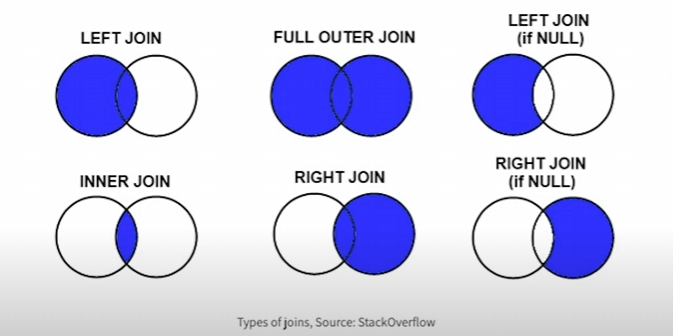

In [71]:
# take out or copy columns
usa = bios[bios["born_country"] == "USA"].copy()
gbr = bios[bios["born_country"] == "GBR"].copy()

In [74]:
usa.head(10) # just show the atheletes from USA

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date
54,55,Monique Javer,1967-07-22,Burlingame,California,USA,Great Britain,177.0,64.0,NaN
960,964,Xóchitl Escobedo,1968-09-17,West Covina,California,USA,Mexico,170.0,60.0,NaN
961,965,Angélica Gavaldón,1973-10-03,El Centro,California,USA,Mexico,160.0,54.0,NaN
1231,1238,Bert Schneider,1897-07-01,Cleveland,Ohio,USA,Canada,NaN,NaN,1986-02-20
1345,1352,Laura Berg,1975-01-06,Santa Fe Springs,California,USA,United States,168.0,61.0,NaN
1346,1353,Gillian Boxx,1973-09-01,Fontana,California,USA,United States,170.0,NaN,NaN
1356,1363,Sheila Cornell-Douty,1962-02-26,Encino,California,USA,United States,175.0,81.0,NaN
1365,1372,Lisa Fernandez,1971-02-22,Long Beach,California,USA,United States,167.0,77.0,NaN
1371,1378,Michele Granger,1970-01-15,Placentia,California,USA,United States,180.0,NaN,NaN
1375,1382,Lori Harrigan,1970-09-05,Anaheim,California,USA,United States,182.0,99.0,NaN


In [75]:
gbr.head(10)

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date
4,5,Albert Canet,1878-04-17,Wandsworth,England,GBR,France,NaN,NaN,1930-07-25
37,38,Helen Aitchison,1881-12-06,Sunderland,England,GBR,Great Britain,NaN,NaN,1947-05-26
38,39,Geraldine Beamish,1883-06-23,Forest Gate,England,GBR,Great Britain,NaN,NaN,1972-05-10
39,40,Dora Boothby,1881-08-02,Finchley,England,GBR,Great Britain,NaN,NaN,1970-02-22
40,41,Julie Bradbury,1967-02-12,Oxford,England,GBR,Great Britain,175.0,64.0,NaN
42,43,Mildred Coles,1876-04-09,Cranbrook,England,GBR,Great Britain,NaN,NaN,1937-02-24
43,44,Evelyn Colyer,1902-08-16,Wandsworth,England,GBR,Great Britain,NaN,NaN,1930-11-04
44,45,Charlotte Cooper,1870-09-22,Ealing,England,GBR,Great Britain,NaN,NaN,1966-10-10
45,46,Phyllis Covell,1895-05-22,Paddington,England,GBR,Great Britain,NaN,NaN,1982-10-28
46,47,Gladys Eastlake-Smith,1883-08-14,Lewisham,England,GBR,Great Britain,NaN,NaN,1941-09-18


In [77]:
# joining (concat) datasets together
usa_and_gbr = pd.concat([usa, gbr])

usa_and_gbr.head()

,athlete_id,name,born_date,born_city,born_region,born_country,NOC,height_cm,weight_kg,died_date
54,55,Monique Javer,1967-07-22,Burlingame,California,USA,Great Britain,177.0,64.0,NaN
960,964,Xóchitl Escobedo,1968-09-17,West Covina,California,USA,Mexico,170.0,60.0,NaN
961,965,Angélica Gavaldón,1973-10-03,El Centro,California,USA,Mexico,160.0,54.0,NaN
1231,1238,Bert Schneider,1897-07-01,Cleveland,Ohio,USA,Canada,NaN,NaN,1986-02-20
1345,1352,Laura Berg,1975-01-06,Santa Fe Springs,California,USA,United States,168.0,61.0,NaN


# Handling Null Values

In [78]:
coffee

,Day,Coffee Type,Units Sold,price,revenue
0,Monday,Espresso,25,3.99,99.75
1,Monday,Latte,10,5.99,59.90
2,Tuesday,Espresso,30,3.99,119.70
3,Tuesday,Latte,20,5.99,119.80
4,Wednesday,Espresso,35,3.99,139.65
5,Wednesday,Latte,25,5.99,149.75
6,Thursday,Espresso,40,3.99,159.60
7,Thursday,Latte,30,5.99,179.70
8,Friday,Espresso,45,3.99,179.55
9,Friday,Latte,35,5.99,209.65


In [79]:
# turn some values into NaN
coffee.loc[[0, 1], "Units Sold"] = np.nan # choose row 0, 1 of 'Units Sold' turn into NaN
# np.nan : numpy method to turn values into Nan

coffee

,Day,Coffee Type,Units Sold,price,revenue
0,Monday,Espresso,NaN,3.99,99.75
1,Monday,Latte,NaN,5.99,59.90
2,Tuesday,Espresso,30.0,3.99,119.70
3,Tuesday,Latte,20.0,5.99,119.80
4,Wednesday,Espresso,35.0,3.99,139.65
5,Wednesday,Latte,25.0,5.99,149.75
6,Thursday,Espresso,40.0,3.99,159.60
7,Thursday,Latte,30.0,5.99,179.70
8,Friday,Espresso,45.0,3.99,179.55
9,Friday,Latte,35.0,5.99,209.65


In [ ]:
# impute (replace) the NaN values
coffee.fillna(coffee["Units Sold"].mean()) # .fillna() : fill NaN values
# .mean() : fill the NaN with the mean of the column

,Day,Coffee Type,Units Sold,price,revenue
0,Monday,Espresso,35.0,3.99,99.75
1,Monday,Latte,35.0,5.99,59.90
2,Tuesday,Espresso,30.0,3.99,119.70
3,Tuesday,Latte,20.0,5.99,119.80
4,Wednesday,Espresso,35.0,3.99,139.65
5,Wednesday,Latte,25.0,5.99,149.75
6,Thursday,Espresso,40.0,3.99,159.60
7,Thursday,Latte,30.0,5.99,179.70
8,Friday,Espresso,45.0,3.99,179.55
9,Friday,Latte,35.0,5.99,209.65


In [84]:
# drop rows with NaN
coffee.dropna(subset=["Units Sold"]) # subsets= : only drop rows if it's in a specific column

,Day,Coffee Type,Units Sold,price,revenue
0,Monday,Espresso,35.0,3.99,99.75
1,Monday,Latte,35.0,5.99,59.90
2,Tuesday,Espresso,30.0,3.99,119.70
3,Tuesday,Latte,20.0,5.99,119.80
4,Wednesday,Espresso,35.0,3.99,139.65
5,Wednesday,Latte,25.0,5.99,149.75
6,Thursday,Espresso,40.0,3.99,159.60
7,Thursday,Latte,30.0,5.99,179.70
8,Friday,Espresso,45.0,3.99,179.55
9,Friday,Latte,35.0,5.99,209.65


In [87]:
coffee.loc[[3, 4], "price"] = np.nan

coffee

,Day,Coffee Type,Units Sold,price,revenue
0,Monday,Espresso,35.0,3.99,99.75
1,Monday,Latte,35.0,5.99,59.90
2,Tuesday,Espresso,30.0,3.99,119.70
3,Tuesday,Latte,20.0,NaN,119.80
4,Wednesday,Espresso,35.0,NaN,139.65
5,Wednesday,Latte,25.0,5.99,149.75
6,Thursday,Espresso,40.0,3.99,159.60
7,Thursday,Latte,30.0,5.99,179.70
8,Friday,Espresso,45.0,3.99,179.55
9,Friday,Latte,35.0,5.99,209.65


In [89]:
# get the rows with NaN
coffee.isna() # show each values as True or False

,Day,Coffee Type,Units Sold,price,revenue
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,True,False
4,False,False,False,True,False
5,False,False,False,False,False
6,False,False,False,False,False
7,False,False,False,False,False
8,False,False,False,False,False
9,False,False,False,False,False


In [92]:
coffee[coffee["price"].isna()] # check a column with NaN

,Day,Coffee Type,Units Sold,price,revenue
3,Tuesday,Latte,20.0,NaN,119.80
4,Wednesday,Espresso,35.0,NaN,139.65


In [93]:
coffee[coffee["price"].notna()] # check a column with no NaN

,Day,Coffee Type,Units Sold,price,revenue
0,Monday,Espresso,35.0,3.99,99.75
1,Monday,Latte,35.0,5.99,59.90
2,Tuesday,Espresso,30.0,3.99,119.70
5,Wednesday,Latte,25.0,5.99,149.75
6,Thursday,Espresso,40.0,3.99,159.60
7,Thursday,Latte,30.0,5.99,179.70
8,Friday,Espresso,45.0,3.99,179.55
9,Friday,Latte,35.0,5.99,209.65
10,Saturday,Espresso,45.0,3.99,179.55
11,Saturday,Latte,35.0,5.99,209.65
